In [1]:
"""
FIND-S Algorithm
=================
Learns the maximally specific hypothesis consistent with all positive
training examples. Negative examples are ignored.

Dataset:
    Online Course Enrollment

Hypothesis notation:
    '?' -> any value is acceptable for this attribute
    '0' -> no value is acceptable yet
    'x' -> a specific required value
"""


def find_s(training_data, target_col="Enroll", positive_label="Yes"):
    """
    training_data: list of dictionaries, each representing one training example.
                   Must include the target column.

    Returns:
        The final hypothesis as a dictionary {attribute: value}.
    """

    attributes = [
        a for a in training_data[0].keys()
        if a != target_col
    ]

    # Step 1: Initialize hypothesis to the most specific hypothesis
    hypothesis = {
        attr: "0"
        for attr in attributes
    }

    print(f"h0 (initial) : {hypothesis}\n")

    # Step 2 & 3: Process each training example
    for i, example in enumerate(training_data, start=1):

        label = example[target_col]

        # Negative examples are ignored
        if label != positive_label:
            print(f"Example {i} ({label}): negative -> ignored")
            continue

        # Process positive example
        for attr in attributes:

            if hypothesis[attr] == "0":
                # First positive example:
                # adopt its value
                hypothesis[attr] = example[attr]

            elif hypothesis[attr] != example[attr]:
                # If values differ, generalize to '?'
                hypothesis[attr] = "?"

            # Otherwise, keep the existing value

        print(
            f"Example {i} ({label}): "
            f"positive -> h{i} = {hypothesis}"
        )

    print(f"\nFinal hypothesis: {hypothesis}")

    return hypothesis


if __name__ == "__main__":

    # ---------------------------------------------------------
    # ONLINE COURSE ENROLLMENT DATASET
    # ---------------------------------------------------------

    training_data = [

        {
            "CourseType": "Programming",
            "Difficulty": "Beginner",
            "Duration": "Short",
            "Rating": "High",
            "Price": "Low",
            "Schedule": "Flexible",
            "Enroll": "Yes"
        },

        {
            "CourseType": "Programming",
            "Difficulty": "Beginner",
            "Duration": "Medium",
            "Rating": "High",
            "Price": "Low",
            "Schedule": "Flexible",
            "Enroll": "Yes"
        },

        {
            "CourseType": "Design",
            "Difficulty": "Beginner",
            "Duration": "Short",
            "Rating": "High",
            "Price": "Low",
            "Schedule": "Flexible",
            "Enroll": "Yes"
        },

        {
            "CourseType": "Programming",
            "Difficulty": "Advanced",
            "Duration": "Long",
            "Rating": "Low",
            "Price": "High",
            "Schedule": "Fixed",
            "Enroll": "No"
        },

        {
            "CourseType": "Marketing",
            "Difficulty": "Intermediate",
            "Duration": "Medium",
            "Rating": "Medium",
            "Price": "High",
            "Schedule": "Fixed",
            "Enroll": "No"
        },

        {
            "CourseType": "Programming",
            "Difficulty": "Intermediate",
            "Duration": "Medium",
            "Rating": "High",
            "Price": "Low",
            "Schedule": "Flexible",
            "Enroll": "Yes"
        },

    ]

    # Run FIND-S
    final_hypothesis = find_s(training_data)


h0 (initial) : {'CourseType': '0', 'Difficulty': '0', 'Duration': '0', 'Rating': '0', 'Price': '0', 'Schedule': '0'}

Example 1 (Yes): positive -> h1 = {'CourseType': 'Programming', 'Difficulty': 'Beginner', 'Duration': 'Short', 'Rating': 'High', 'Price': 'Low', 'Schedule': 'Flexible'}
Example 2 (Yes): positive -> h2 = {'CourseType': 'Programming', 'Difficulty': 'Beginner', 'Duration': '?', 'Rating': 'High', 'Price': 'Low', 'Schedule': 'Flexible'}
Example 3 (Yes): positive -> h3 = {'CourseType': '?', 'Difficulty': 'Beginner', 'Duration': '?', 'Rating': 'High', 'Price': 'Low', 'Schedule': 'Flexible'}
Example 4 (No): negative -> ignored
Example 5 (No): negative -> ignored
Example 6 (Yes): positive -> h6 = {'CourseType': '?', 'Difficulty': '?', 'Duration': '?', 'Rating': 'High', 'Price': 'Low', 'Schedule': 'Flexible'}

Final hypothesis: {'CourseType': '?', 'Difficulty': '?', 'Duration': '?', 'Rating': 'High', 'Price': 'Low', 'Schedule': 'Flexible'}



Step-by-step hypothesis:
h0: {'CourseType': '0', 'Difficulty': '0', 'Duration': '0', 'Rating': '0', 'Price': '0', 'Schedule': '0'}
h1: {'CourseType': 'Programming', 'Difficulty': 'Beginner', 'Duration': 'Short', 'Rating': 'High', 'Price': 'Low', 'Schedule': 'Flexible'}
h2: {'CourseType': 'Programming', 'Difficulty': 'Beginner', 'Duration': '?', 'Rating': 'High', 'Price': 'Low', 'Schedule': 'Flexible'}
h3: {'CourseType': '?', 'Difficulty': 'Beginner', 'Duration': '?', 'Rating': 'High', 'Price': 'Low', 'Schedule': 'Flexible'}
Ex4 (neg): {'CourseType': '?', 'Difficulty': 'Beginner', 'Duration': '?', 'Rating': 'High', 'Price': 'Low', 'Schedule': 'Flexible'}
Ex5 (neg): {'CourseType': '?', 'Difficulty': 'Beginner', 'Duration': '?', 'Rating': 'High', 'Price': 'Low', 'Schedule': 'Flexible'}
h6: {'CourseType': '?', 'Difficulty': '?', 'Duration': '?', 'Rating': 'High', 'Price': 'Low', 'Schedule': 'Flexible'}

Final hypothesis:
CourseType: ?
Difficulty: ?
Duration: ?
Rating: High
Price: Low
Sche

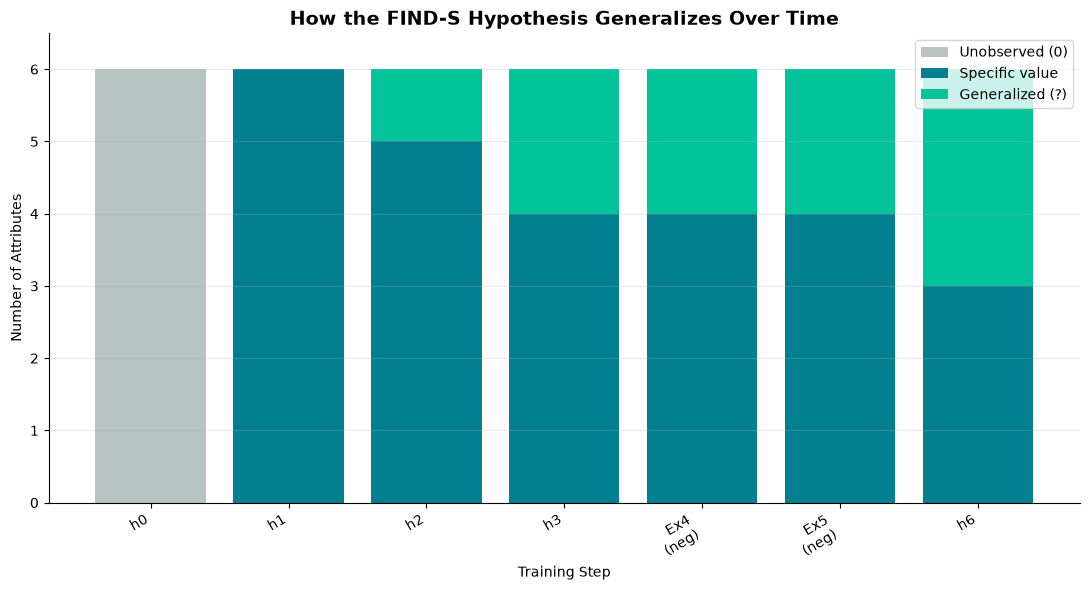

Saved: specificity_trend.png


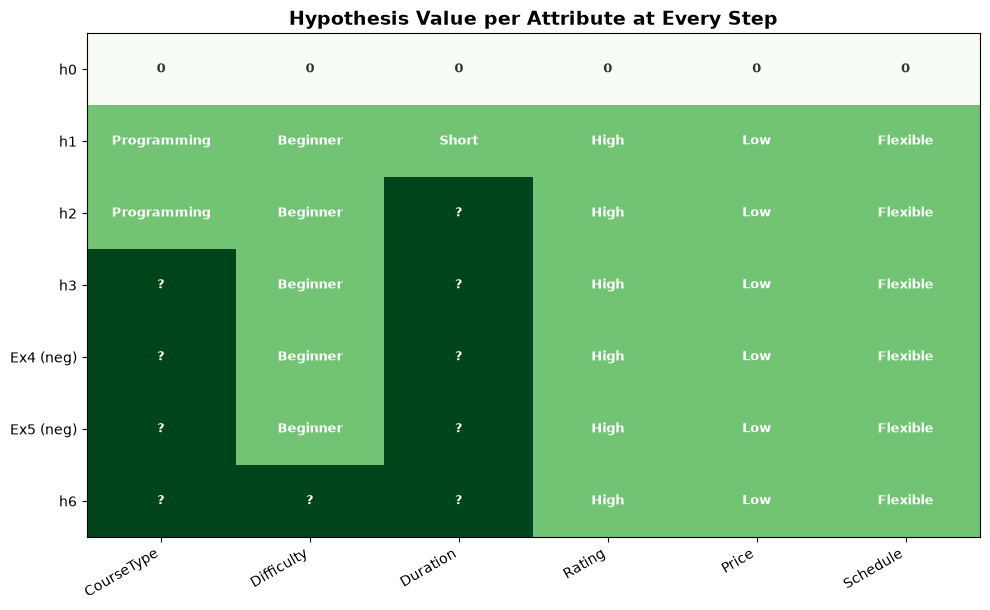

Saved: hypothesis_heatmap.png


In [6]:
import numpy as np
import matplotlib.pyplot as plt


def find_s_with_history(training_data, target_col="Enroll", positive_label="Yes"):
    attributes = [a for a in training_data[0].keys() if a != target_col]
    hypothesis = {attr: "0" for attr in attributes}

    history = [("h0", dict(hypothesis), None)]

    for i, example in enumerate(training_data, start=1):
        label = example[target_col]

        if label != positive_label:
            history.append((f"Ex{i}\n(neg)", dict(hypothesis), False))
            continue

        for attr in attributes:
            if hypothesis[attr] == "0":
                hypothesis[attr] = example[attr]
            elif hypothesis[attr] != example[attr]:
                hypothesis[attr] = "?"

        history.append((f"h{i}", dict(hypothesis), True))

    return hypothesis, history, attributes


def plot_specificity_trend(
    history,
    attributes,
    save_as="specificity_trend.png"
):
    steps = [h[0] for h in history]

    unobserved = []
    specific = []
    general = []

    for _, hyp, _ in history:
        generalized = sum(1 for v in hyp.values() if v == "?")
        unobserved_count = sum(1 for v in hyp.values() if v == "0")
        specific_count = len(attributes) - generalized - unobserved_count

        unobserved.append(unobserved_count)
        specific.append(specific_count)
        general.append(generalized)

    x = np.arange(len(steps))

    fig, ax = plt.subplots(figsize=(11, 6))

    ax.bar(
        x,
        unobserved,
        label="Unobserved (0)",
        color="#B7C4C2"
    )

    ax.bar(
        x,
        specific,
        bottom=unobserved,
        label="Specific value",
        color="#028090"
    )

    bottom = np.array(unobserved) + np.array(specific)

    ax.bar(
        x,
        general,
        bottom=bottom,
        label="Generalized (?)",
        color="#02C39A"
    )

    ax.set_xticks(x)
    ax.set_xticklabels(steps, rotation=30, ha="right")
    ax.set_xlabel("Training Step")
    ax.set_ylabel("Number of Attributes")
    ax.set_title(
        "How the FIND-S Hypothesis Generalizes Over Time",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_ylim(0, len(attributes) + 0.5)
    ax.legend(loc="upper right")
    ax.grid(axis="y", alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()
    plt.savefig(save_as, dpi=150, bbox_inches="tight")
    plt.show()

    print(f"Saved: {save_as}")


def plot_hypothesis_heatmap(
    history,
    attributes,
    save_as="hypothesis_heatmap.png"
):
    grid = []

    for _, hyp, _ in history:
        row = []

        for attr in attributes:
            if hyp[attr] == "0":
                value = 0
            elif hyp[attr] == "?":
                value = 2
            else:
                value = 1

            row.append(value)

        grid.append(row)

    grid = np.array(grid)

    fig, ax = plt.subplots(
        figsize=(10, 0.6 * len(history) + 2)
    )

    ax.imshow(
        grid,
        cmap="Greens",
        aspect="auto",
        vmin=0,
        vmax=2
    )

    ax.set_xticks(range(len(attributes)))
    ax.set_xticklabels(
        attributes,
        rotation=30,
        ha="right"
    )

    ax.set_yticks(range(len(history)))
    ax.set_yticklabels(
        [h[0].replace("\n", " ") for h in history]
    )

    for i, (_, hyp, _) in enumerate(history):
        for j, attr in enumerate(attributes):
            color = "white" if grid[i, j] >= 1 else "#333333"

            ax.text(
                j,
                i,
                hyp[attr],
                ha="center",
                va="center",
                fontsize=9,
                color=color,
                fontweight="bold"
            )

    ax.set_title(
        "Hypothesis Value per Attribute at Every Step",
        fontsize=14,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.savefig(save_as, dpi=150, bbox_inches="tight")
    plt.show()

    print(f"Saved: {save_as}")


if __name__ == "__main__":

    training_data = [
        {
            "CourseType": "Programming",
            "Difficulty": "Beginner",
            "Duration": "Short",
            "Rating": "High",
            "Price": "Low",
            "Schedule": "Flexible",
            "Enroll": "Yes"
        },
        {
            "CourseType": "Programming",
            "Difficulty": "Beginner",
            "Duration": "Medium",
            "Rating": "High",
            "Price": "Low",
            "Schedule": "Flexible",
            "Enroll": "Yes"
        },
        {
            "CourseType": "Design",
            "Difficulty": "Beginner",
            "Duration": "Short",
            "Rating": "High",
            "Price": "Low",
            "Schedule": "Flexible",
            "Enroll": "Yes"
        },
        {
            "CourseType": "Programming",
            "Difficulty": "Advanced",
            "Duration": "Long",
            "Rating": "Low",
            "Price": "High",
            "Schedule": "Fixed",
            "Enroll": "No"
        },
        {
            "CourseType": "Marketing",
            "Difficulty": "Intermediate",
            "Duration": "Medium",
            "Rating": "Medium",
            "Price": "High",
            "Schedule": "Fixed",
            "Enroll": "No"
        },
        {
            "CourseType": "Programming",
            "Difficulty": "Intermediate",
            "Duration": "Medium",
            "Rating": "High",
            "Price": "Low",
            "Schedule": "Flexible",
            "Enroll": "Yes"
        }
    ]

    final_hypothesis, history, attributes = find_s_with_history(
        training_data
    )

    print("\nStep-by-step hypothesis:")

    for label, hypothesis, _ in history:
        print(
            f"{label.replace(chr(10), ' ')}: "
            f"{hypothesis}"
        )

    print("\nFinal hypothesis:")

    for attribute, value in final_hypothesis.items():
        print(f"{attribute}: {value}")

    plot_specificity_trend(
        history,
        attributes
    )

    plot_hypothesis_heatmap(
        history,
        attributes
    )
